# Notebook 02: Sales Exploratory Data Analysis
**Project:** Walmart Store Sales Forecasting & Business Intelligence System  
**Phase:** Phase 2 — Exploratory Data Analysis & Time-Series Analysis  
**Author:** Lead Data Scientist & Machine Learning Engineer  

---
### Objectives
1. Analyze overall sales distribution, skewness, kurtosis, and extreme values.
2. Characterize negative sales occurrences and verify retail accounting explanations.
3. Compare store-level performance, rankings, physical store size correlations, and store types (A, B, C).
4. Profile department revenue contributions, high-volatility categories, and Pareto concentration curves.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sys.path.append(os.path.abspath(".."))
from src.data_loader import load_processed_data

plt.rcParams['figure.figsize'] = (12, 6)
sns.set_theme(style="whitegrid", palette="muted")
train, test = load_processed_data()
print("Data loaded successfully.")


2026-11-22 15:10:13,945 [INFO] Loading processed datasets from Parquet: E:\MCA projects\Demand-Forecasting\walmart-recruiting-store-sales-forecasting\data\processed


Data loaded successfully.


## 1. Overall Sales Distribution & Skewness

Descriptive Statistics for Weekly_Sales:
Mean:     $15,981.26
Median:   $7,612.03
Std Dev:  $22,711.18
Min:      $-4,988.94
Q1 (25%): $2,079.65
Q3 (75%): $20,205.85
IQR:      $18,126.20
Max:      $693,099.36
Skewness: 3.262 (Severe Right Skew)
Kurtosis: 21.491 (Heavy Leptokurtic Tails)


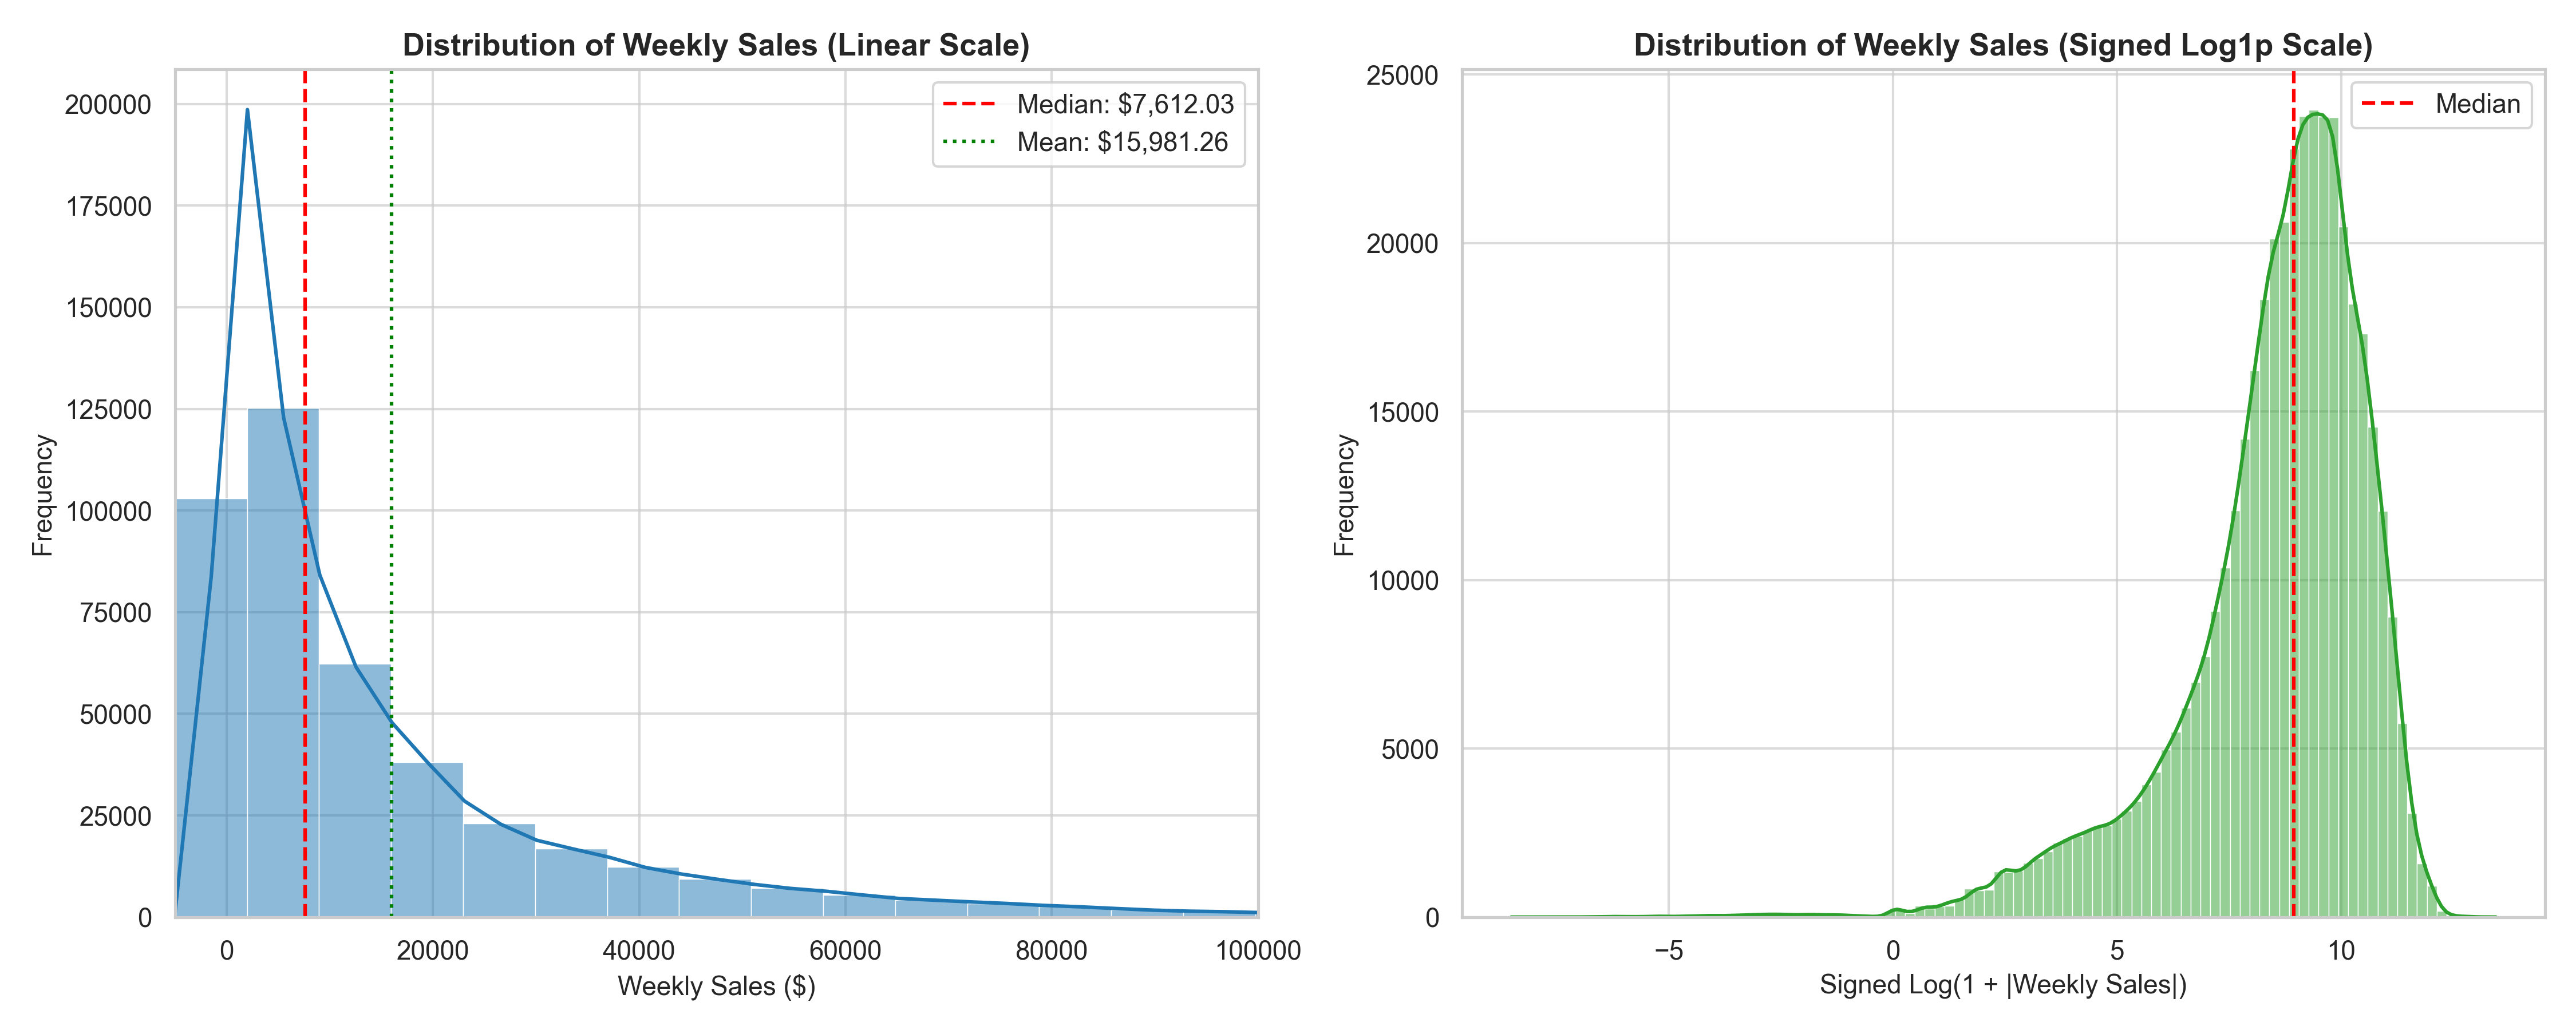

In [2]:
sales = train['Weekly_Sales']
print("Descriptive Statistics for Weekly_Sales:")
print(f"Mean:     ${sales.mean():,.2f}")
print(f"Median:   ${sales.median():,.2f}")
print(f"Std Dev:  ${sales.std():,.2f}")
print(f"Min:      ${sales.min():,.2f}")
print(f"Q1 (25%): ${sales.quantile(0.25):,.2f}")
print(f"Q3 (75%): ${sales.quantile(0.75):,.2f}")
print(f"IQR:      ${sales.quantile(0.75) - sales.quantile(0.25):,.2f}")
print(f"Max:      ${sales.max():,.2f}")
print(f"Skewness: {sales.skew():.3f} (Severe Right Skew)")
print(f"Kurtosis: {sales.kurtosis():.3f} (Heavy Leptokurtic Tails)")

display(Image(filename=os.path.join("..", "outputs", "figures", "fig02_sales_distribution_and_log.png")))


## 2. Negative Sales Investigation

Total Negative Sales Records: 1,285 (0.3048% of train)
Minimum Value: $-4,988.94
Total Negative Sales Sum: $-88,161.56
Stores Affected: 45 / 45
Departments Affected: 50 / 81

Top 10 Departments by Negative Sales Count:
      count       sum      min
Dept                          
47      254 -53188.06 -3924.00
18      180  -1819.05  -175.54
54      146  -4829.81  -465.08
19       87  -1042.66   -69.56
94       77   -647.78  -173.84
80       68  -4231.48  -590.04
49       67  -1455.98  -326.61
59       44   -411.82   -55.46
72       34  -3047.58  -379.00
78       33   -352.20   -24.00


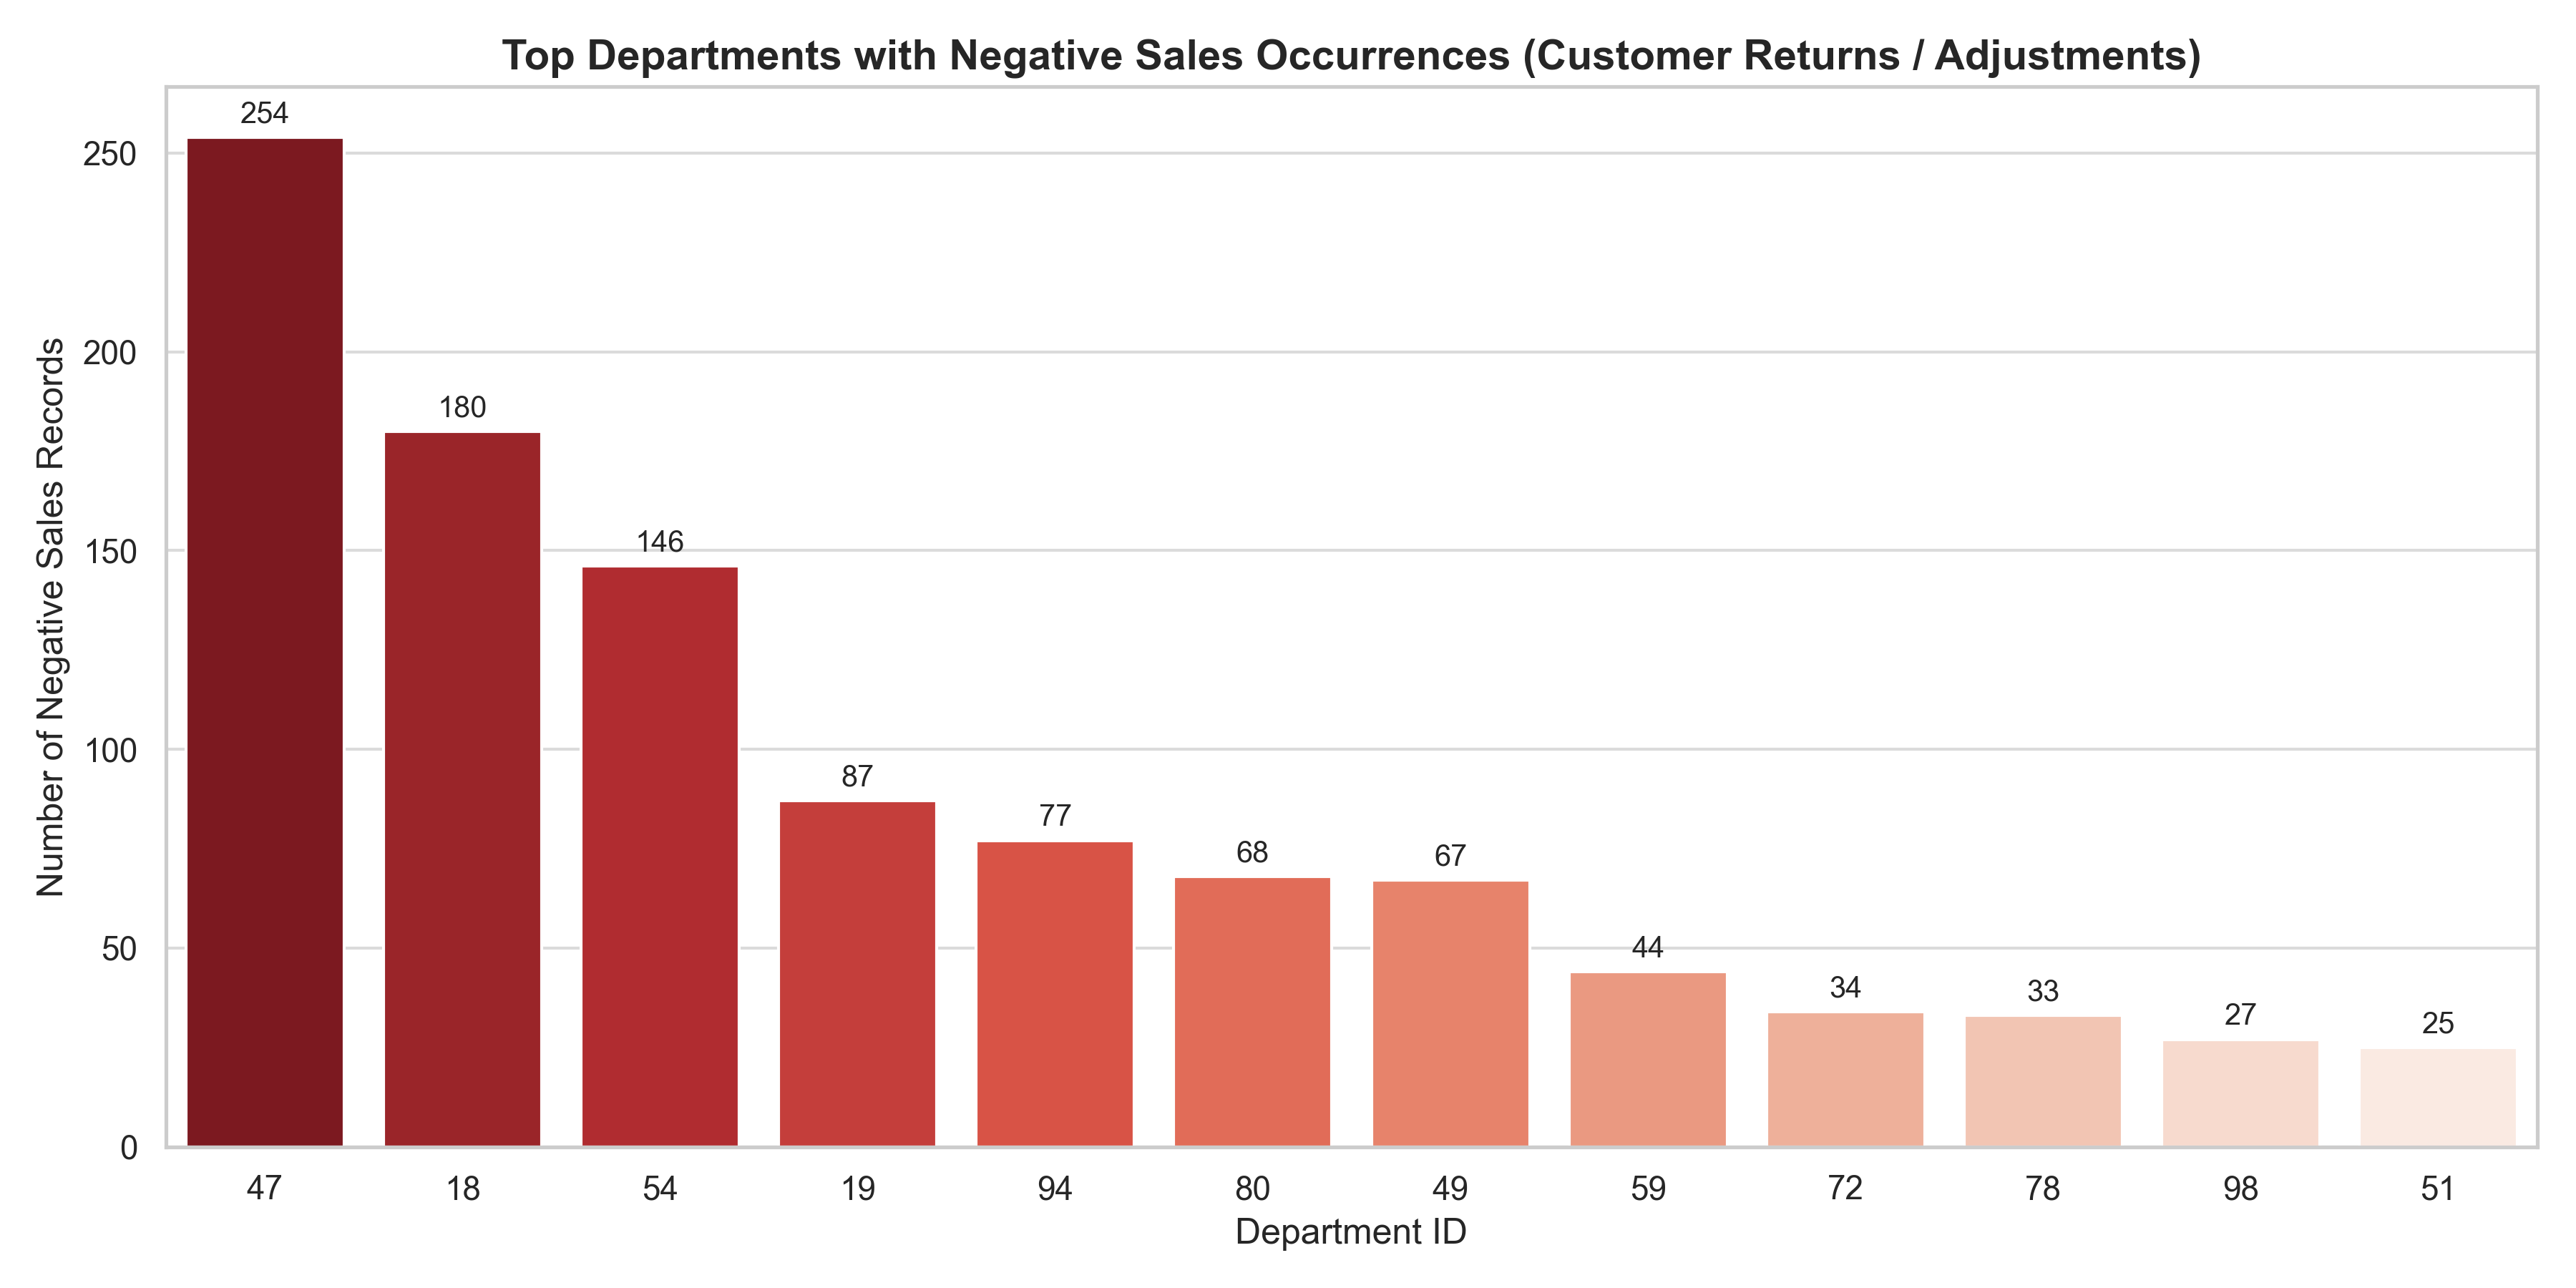

In [3]:
neg_sales = train[train['Weekly_Sales'] < 0]
print(f"Total Negative Sales Records: {len(neg_sales):,} ({len(neg_sales)/len(train)*100:.4f}% of train)")
print(f"Minimum Value: ${neg_sales['Weekly_Sales'].min():,.2f}")
print(f"Total Negative Sales Sum: ${neg_sales['Weekly_Sales'].sum():,.2f}")
print(f"Stores Affected: {neg_sales['Store'].nunique()} / 45")
print(f"Departments Affected: {neg_sales['Dept'].nunique()} / 81")

top_neg = neg_sales.groupby('Dept')['Weekly_Sales'].agg(['count', 'sum', 'min']).sort_values('count', ascending=False).head(10)
print("\nTop 10 Departments by Negative Sales Count:")
print(top_neg)

display(Image(filename=os.path.join("..", "outputs", "figures", "fig03_negative_sales_by_dept.png")))


## 3. Store Performance & Ranking

Top 5 Performing Stores by Total Revenue:
    Store Type    Size  count           sum          mean     median  \
19     20    A  203742  10214  3.013978e+08  29508.301592  16249.780   
3       4    A  205863  10272  2.995440e+08  29161.210415  15116.810   
13     14    A  200898  10040  2.889999e+08  28784.851727  15208.805   
12     13    A  219622  10474  2.865177e+08  27355.136891  14018.455   
1       2    A  202307  10238  2.753824e+08  26898.070031  14333.530   

             std  
19  35661.530620  
3   34583.677814  
13  36911.116744  
12  33853.474638  
1   33077.612059  

Bottom 5 Performing Stores by Total Revenue:


    Store Type   Size  count          sum         mean    median           std
37     38    C  39690   7362  55159626.42  7492.478460   751.255  12733.356273
35     36    A  39910   6222  53412214.97  8584.412563  1903.285  12995.813451
4       5    B  34875   8999  45475688.90  5053.415813  2582.660   8068.221050
43     44    C  39910   7169  43293087.84  6038.929814   799.530  10609.468795
32     33    A  39690   6487  37160221.96  5728.414053   912.810   8973.688840


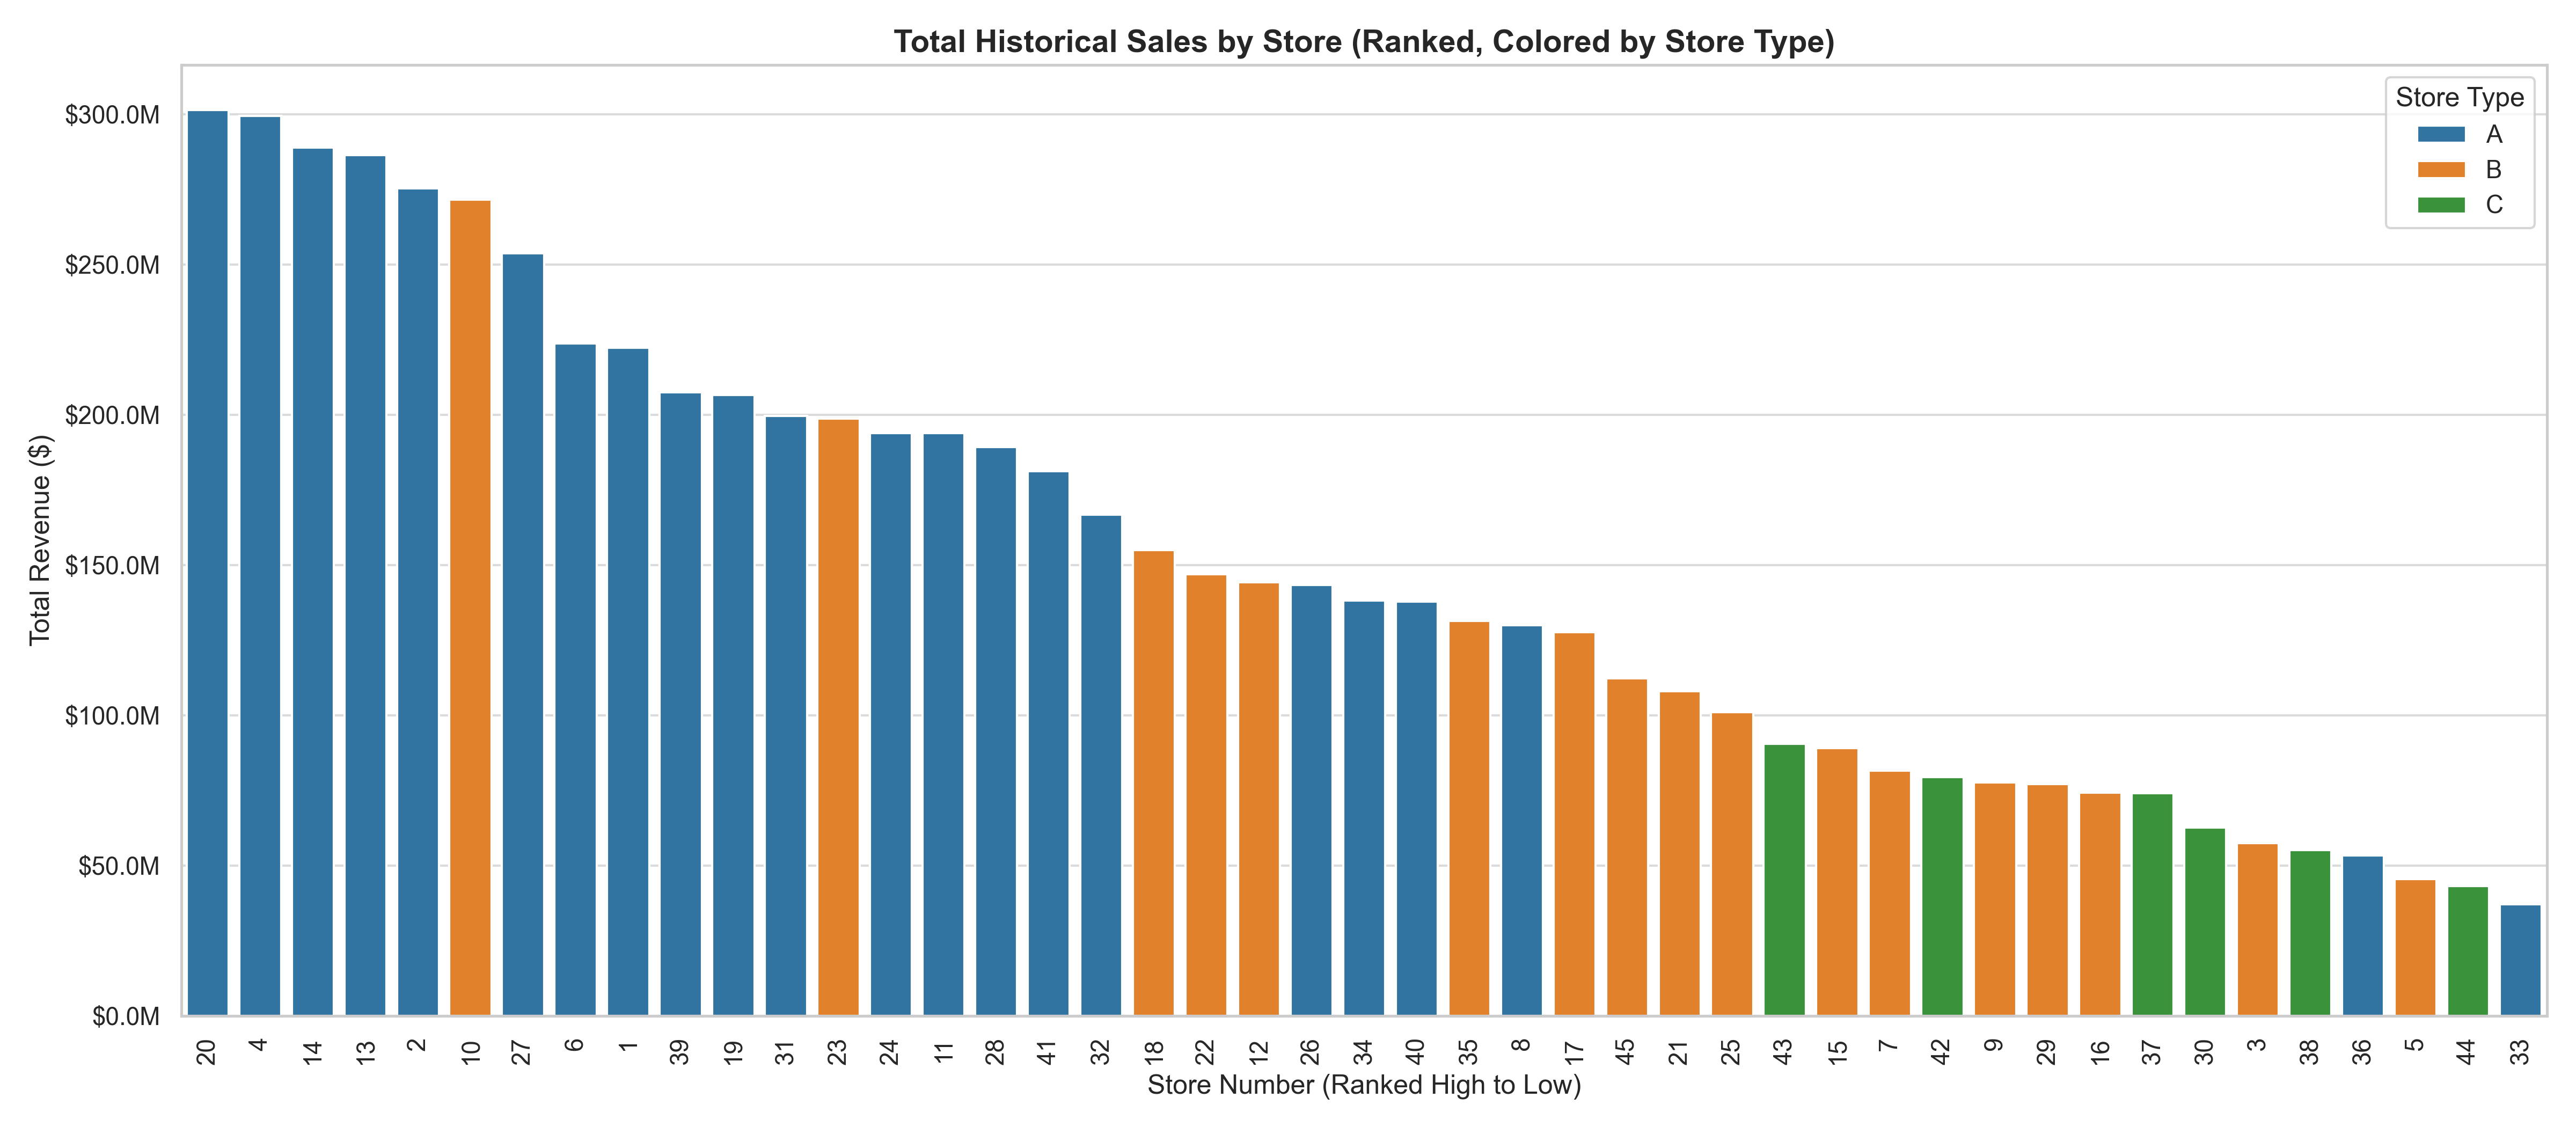

In [4]:
store_perf = train.groupby(['Store', 'Type', 'Size'])['Weekly_Sales'].agg(['count', 'sum', 'mean', 'median', 'std']).reset_index()
store_perf = store_perf.sort_values('sum', ascending=False)
print("Top 5 Performing Stores by Total Revenue:")
print(store_perf.head(5))

print("\nBottom 5 Performing Stores by Total Revenue:")
print(store_perf.tail(5))

display(Image(filename=os.path.join("..", "outputs", "figures", "fig04_store_sales_ranking.png")))


## 4. Store Type & Physical Size Relationship

Performance Summary by Store Type:
       count          mean    median           std           sum  Revenue_Pct
Type                                                                         
A     215478  20099.568043  10105.17  26423.457227  4.331015e+09        64.28
B     163495  12237.075977   6187.87  17203.668989  2.000701e+09        29.70
C      42597   9519.532538   1149.67  15985.351612  4.055035e+08         6.02


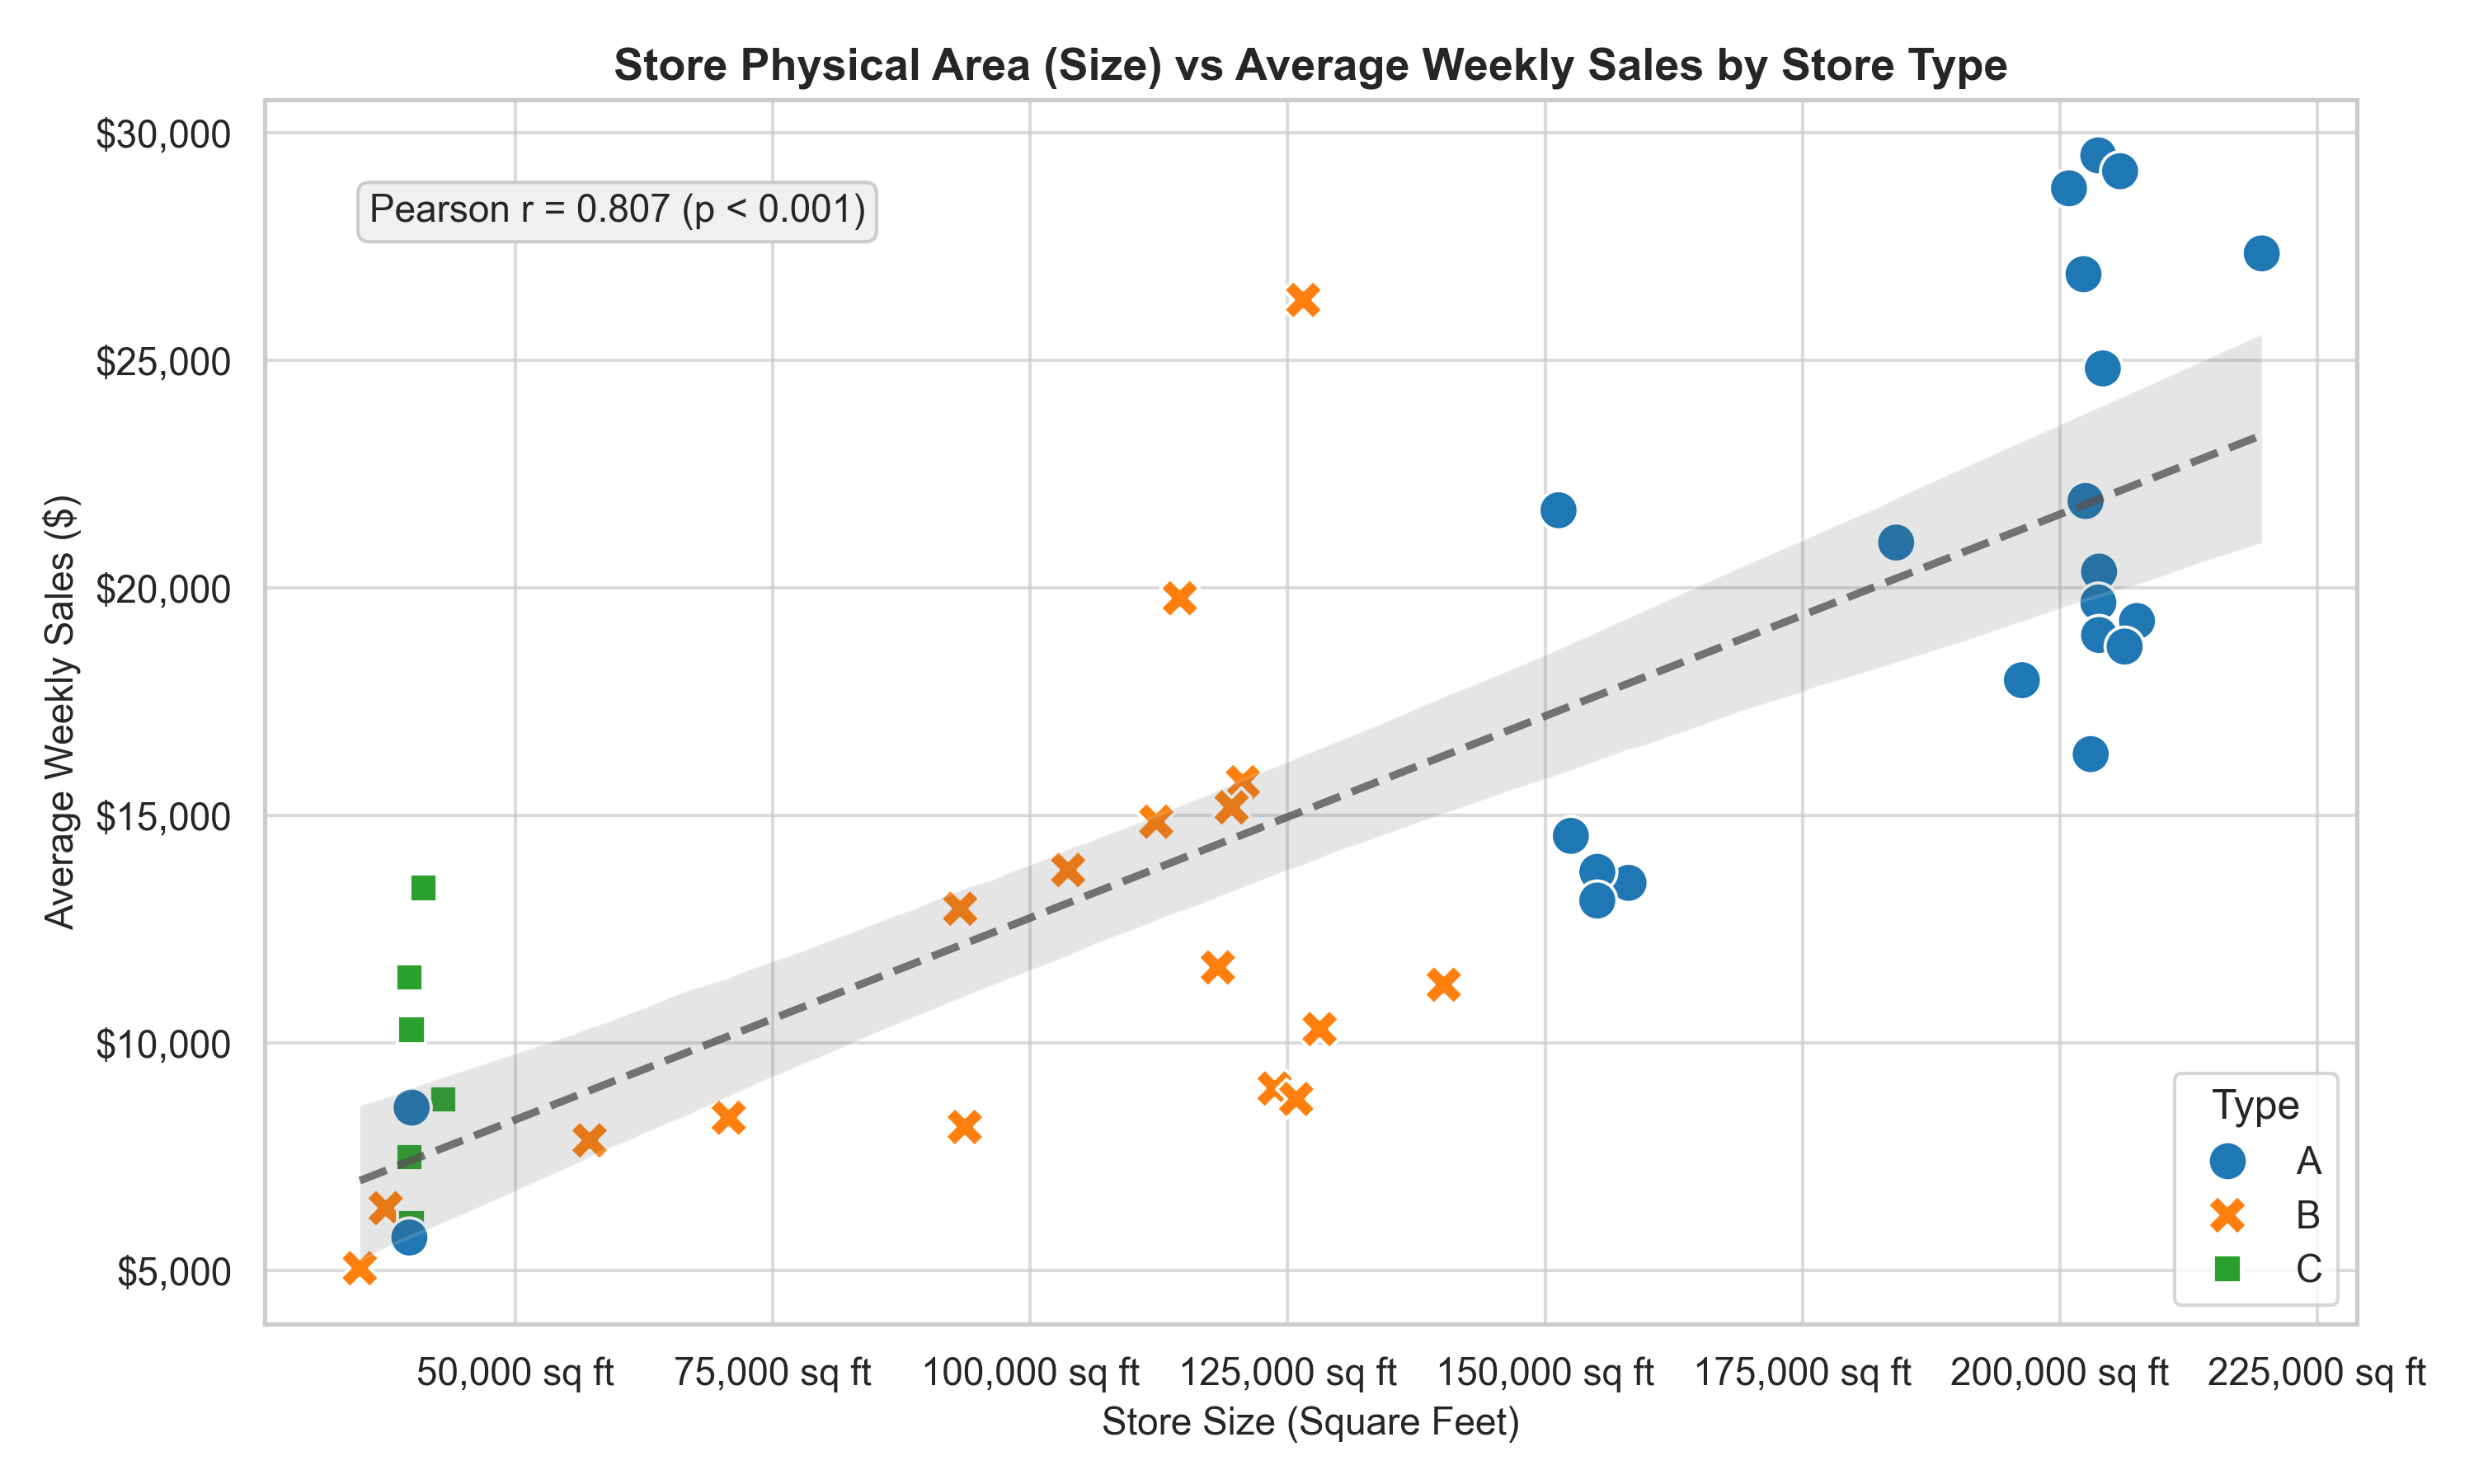

In [5]:
type_summary = train.groupby('Type')['Weekly_Sales'].agg(['count', 'mean', 'median', 'std', 'sum'])
type_summary['Revenue_Pct'] = (type_summary['sum'] / train['Weekly_Sales'].sum() * 100).round(2)
print("Performance Summary by Store Type:")
print(type_summary)

display(Image(filename=os.path.join("..", "outputs", "figures", "fig05_store_type_size_vs_sales.png")))


## 5. Department Revenue & Pareto Concentration

Top 5 Revenue-Generating Departments:
   Dept  count           sum          mean    median
0    92   6435  4.839433e+08  75204.870531  61816.77
1    95   6435  4.493202e+08  69824.423080  60774.39
2    38   6435  3.931181e+08  61090.619568  57336.65
3    72   6046  3.057252e+08  50566.515417  44312.36
4    90   6435  2.910685e+08  45232.084488  40535.79

Bottom 5 Revenue-Generating Departments:
    Dept  count       sum       mean  median
76    51   1394  30572.83  21.931729  11.000
77    78    235   1714.71   7.296638   9.880
78    39     16    177.98  11.123750  10.430
79    43     12     14.32   1.193333   0.750
80    47    646  -4962.93  -7.682554  17.985


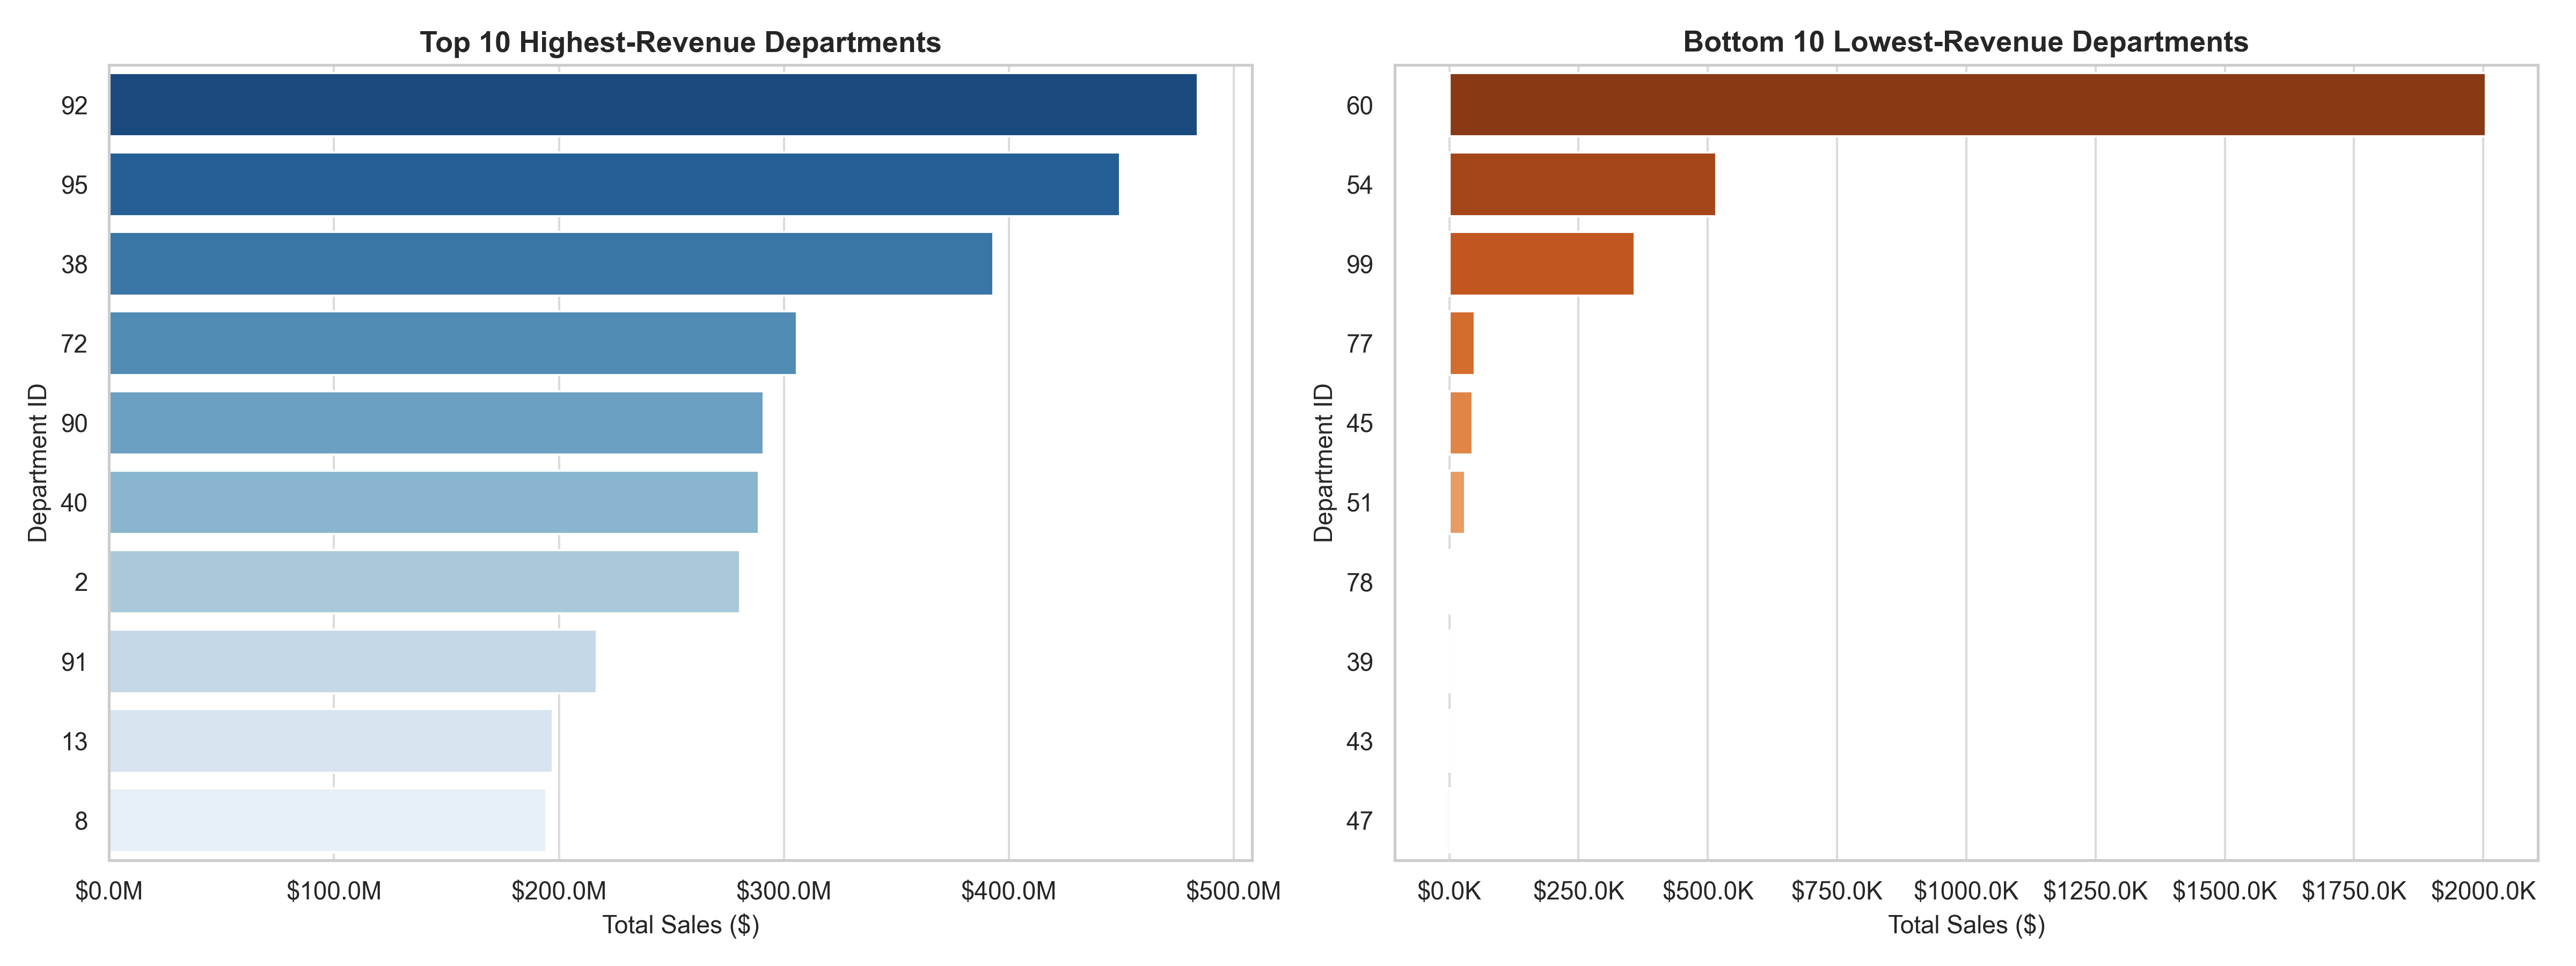

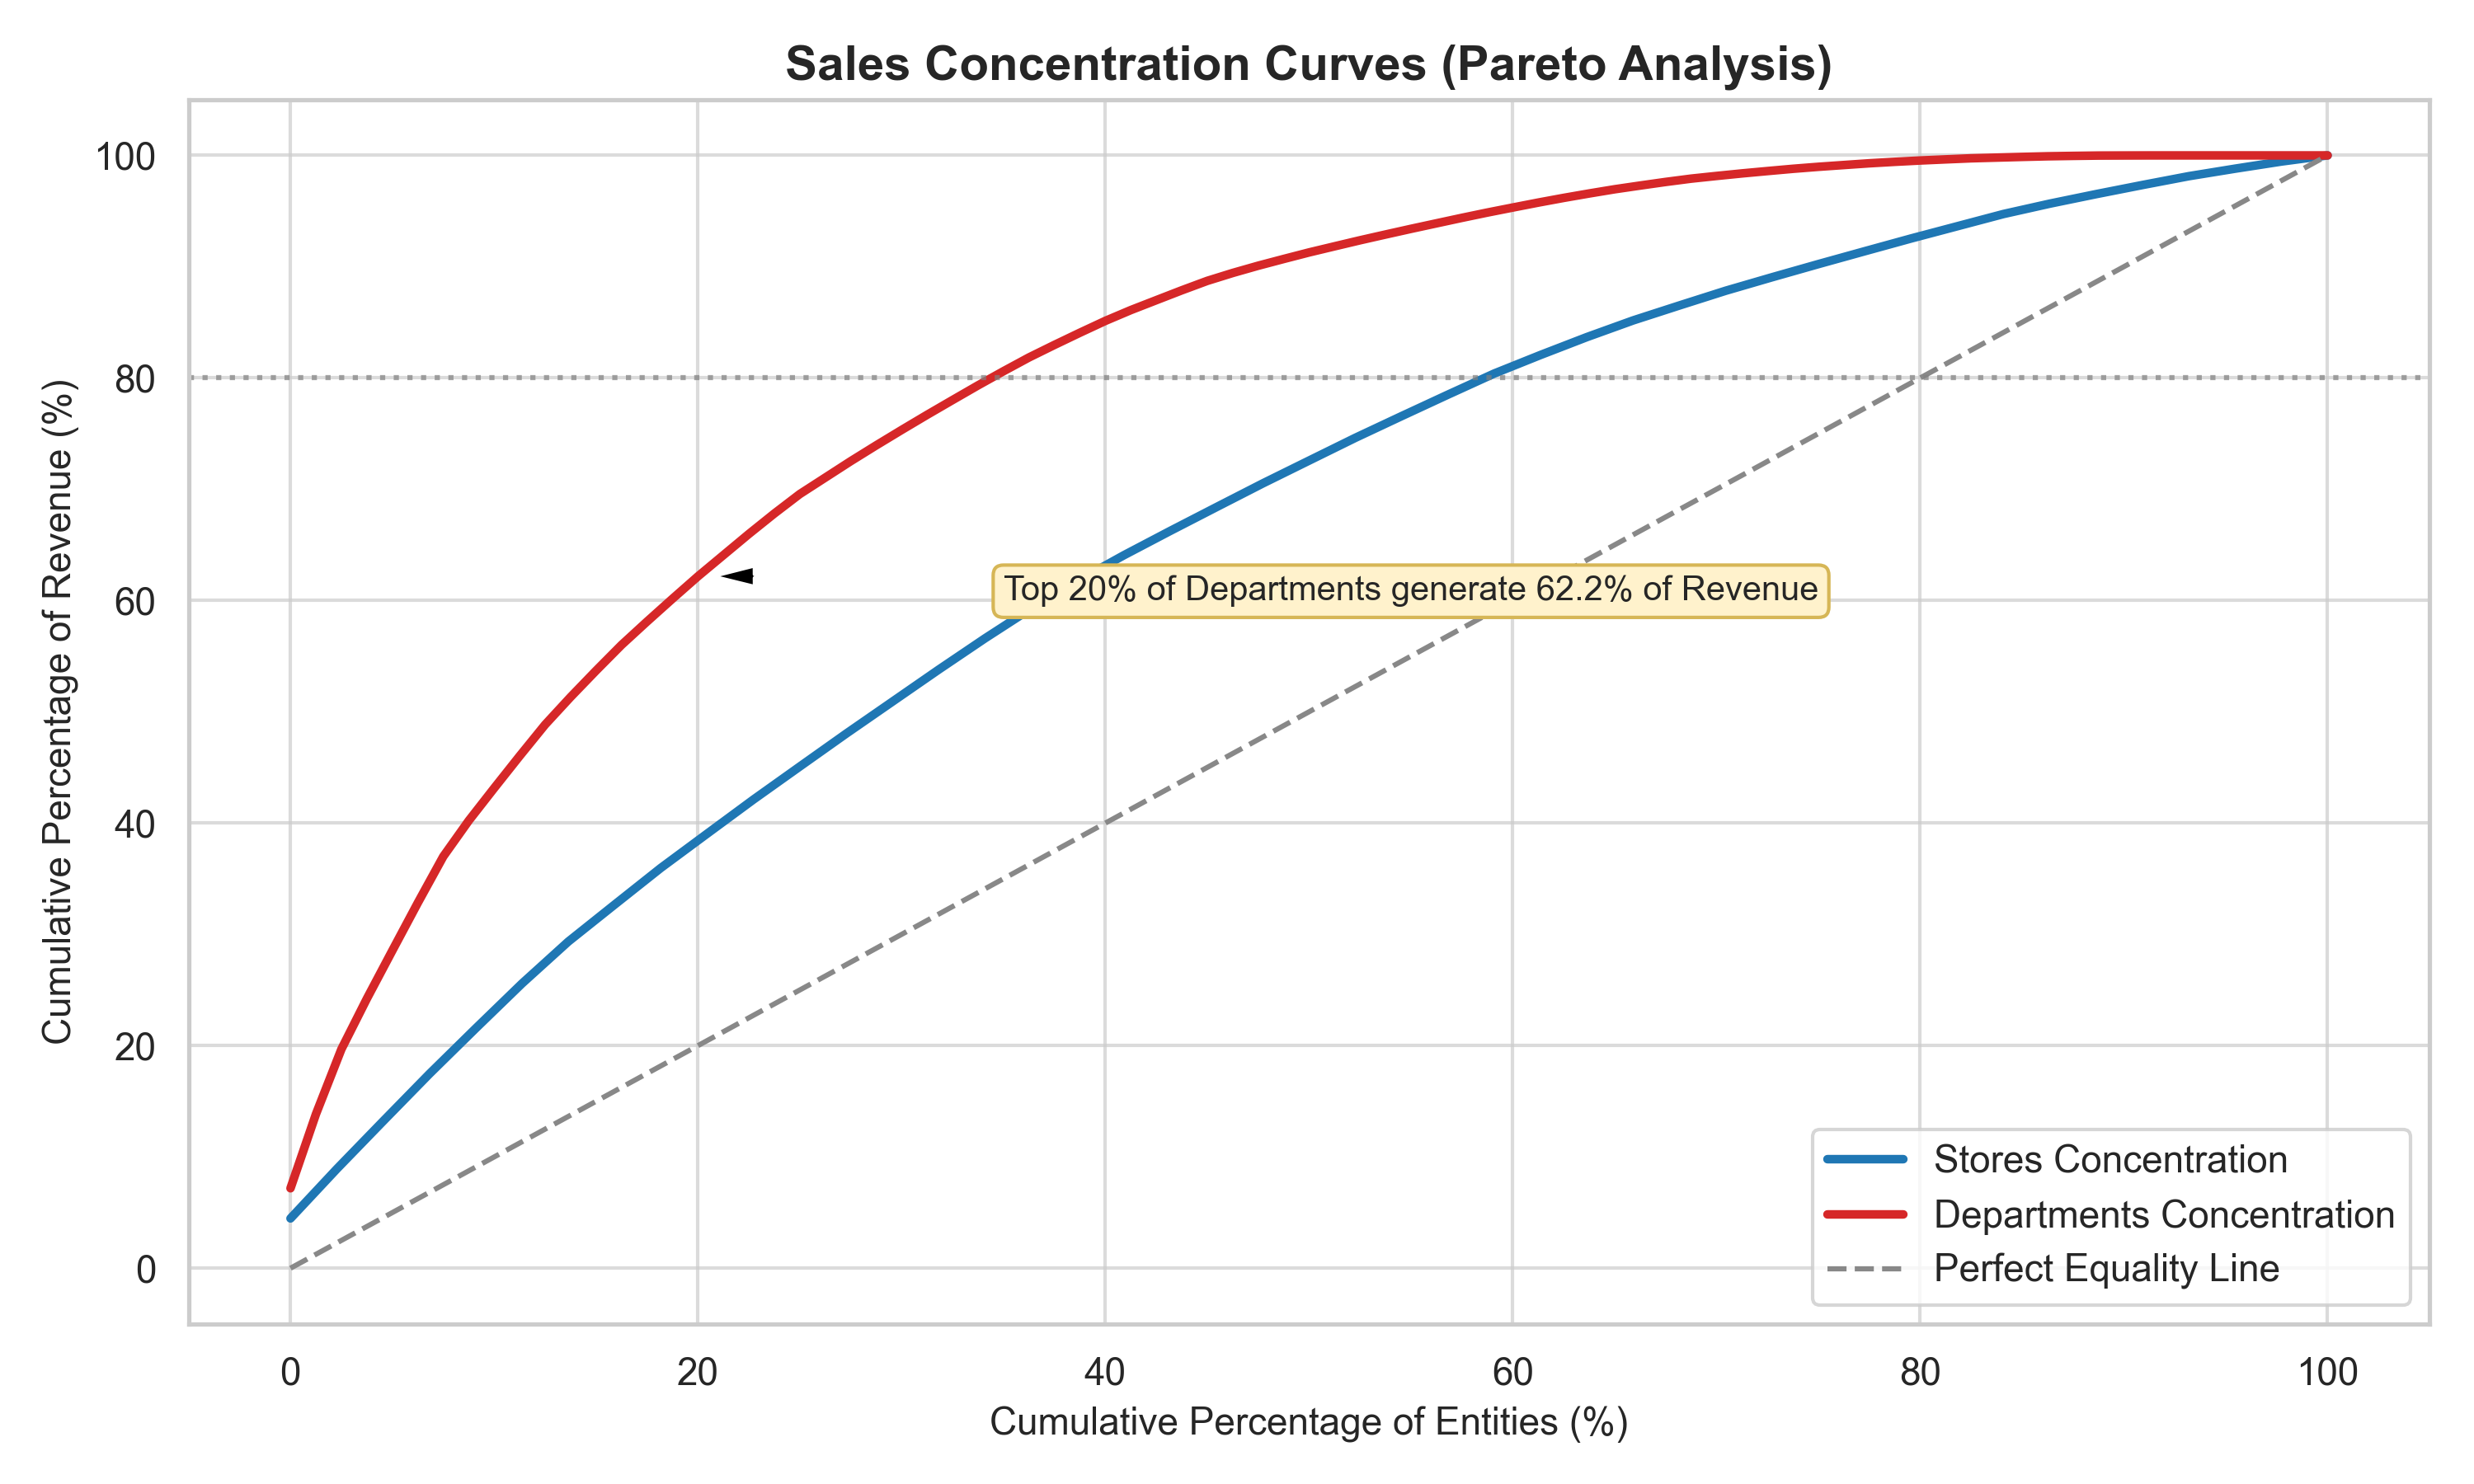

In [6]:
dept_perf = train.groupby('Dept')['Weekly_Sales'].agg(['count', 'sum', 'mean', 'median']).sort_values('sum', ascending=False).reset_index()
print("Top 5 Revenue-Generating Departments:")
print(dept_perf.head(5))

print("\nBottom 5 Revenue-Generating Departments:")
print(dept_perf.tail(5))

display(Image(filename=os.path.join("..", "outputs", "figures", "fig06_top_bottom_departments_revenue.png")))
display(Image(filename=os.path.join("..", "outputs", "figures", "fig07_sales_concentration_pareto.png")))
